In [11]:
from rdkit import Chem
import pandas as pd
from rdkit.Chem import Draw
from rdkit.Chem import Descriptors
from rdkit.Chem import rdFingerprintGenerator
import sqlite3

In [3]:
input = Chem.MolFromSmiles('COC(O)O')

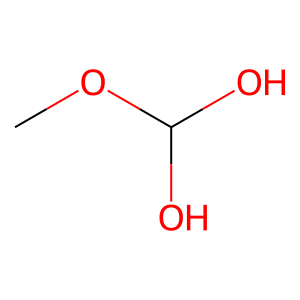

In [4]:
Draw.MolToImage(input)

In [5]:
finger = rdFingerprintGenerator.GetMorganGenerator(radius=2,fpSize=2048).GetFingerprint(input)

In [6]:
chembl = sqlite3.connect('./chembl_36.db')

In [17]:
compound_structures = pd.read_sql_query('SELECT * FROM compound_structures LIMIT 10',chembl,chunksize=10)
assays = pd.read_sql_query('SELECT * FROM assays LIMIT 10',chembl,chunksize=10)
activities = pd.read_sql_query('SELECT * FROM activities LIMIT 10',chembl,chunksize=10)
molecule_dictionary = pd.read_sql_query('SELECT * FROM molecule_dictionary LIMIT 10',chembl,chunksize=10)
target_dictionary = pd.read_sql_query('SELECT * FROM target_dictionary LIMIT 10',chembl,chunksize=10)
component_sequences = pd.read_sql_query('SELECT * FROM component_sequences LIMIT 10',chembl,chunksize=10)
data = [compound_structures, assays,activities,molecule_dictionary,target_dictionary,component_sequences]

In [24]:
for i in data:
    for l in i:
        print(l)

In [13]:
tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'",chembl,chunksize = 10)

activities \
assays \
compound_structures \
molecule_dictionary \
target_dictionary \
component_sequences 

In [16]:
for i in tables:
    print(i)

                      name
0              action_type
1               assay_type
2         chembl_id_lookup
3  confidence_score_lookup
4          curation_lookup
5           chembl_release
6                   source
7        relationship_type
8              target_type
9        variant_sequences
                      name
0        bioassay_ontology
1     data_validity_lookup
2            activity_smid
3     activity_stds_lookup
4     assay_classification
5       atc_classification
6  bio_component_sequences
7      component_sequences
8   protein_classification
9                  domains
                    name
0      go_classification
1  structural_alert_sets
2               products
3         organism_class
4       patent_use_codes
5             usan_stems
6                version
7        cell_dictionary
8                   docs
9      target_dictionary
                  name
0    tissue_dictionary
1  molecule_dictionary
2        activity_supp
3      component_class
4    component_d